In [187]:
# Import libraries
import pandas as pd                  # Data Preprocessing
import matplotlib.pyplot as plt      # Data Visualization
import seaborn as sns                # Data Visualization
import missingno as msno             # Missing Data Visualization
from collections import Counter     # Counting

In [188]:
# Load the dataset

path = r"C:\Users\LENOVO\OneDrive\Desktop\DS_course\Course Materials\Python\python-data-science-lab\EDA\files\Dune Sales Data.csv"
df = pd.read_csv(path)

In [189]:
# Print the top rows
df.head()

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,Unit_Cost,Unit_Price
0,19-Feb-16,High,Segun,29,F,Abia,Accessories,Keyboard,Online,1.0,80.00,109.00
1,20-Feb-16,High,Segun,29,F,Abia,Clothing,Polo shirts,Online,2.0,24.50,28.50
2,27-Feb-16,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,3.67,5.00
3,12-Mar-16,High,Segun,29,F,Abia,Accessories,Keyboard,Online,2.0,87.50,116.50
4,12-Mar-16,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,35.00,41.67


In [190]:
# Print the button rows
df.tail()

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,Unit_Cost,Unit_Price
34862,7-Feb-16,High,Kenny,38,M,Ebonyi,Phones,IPhone,Online,2.0,1160.0,985.50
34863,13-Mar-15,High,Kenny,38,M,Ebonyi,Phones,IPhone,Online,1.0,2049.0,1583.00
34864,5-Apr-15,High,Kenny,38,M,Ebonyi,Phones,IPhone,Online,3.0,683.0,560.67
34865,30-Aug-15,High,Kenny,38,M,Ebonyi,Phones,IPhone,Online,1.0,2320.0,1568.00
34866,NaN,NaN,NaN,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [191]:
# Dimensionality of the data - The number of rows and columns
df.shape


(34867, 12)

In [192]:
# Examine the columns/features of the data
df.columns

Index(['Date', 'Customer', 'Sales Person', 'Customer_Age', 'Customer_Gender',
       'State', 'Product_Category', 'Sub_Category', 'Payment Option',
       'Quantity', 'Unit_Cost', 'Unit_Price'],
      dtype='object')

In [193]:
# Investigate the dataset for anomalies
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34867 entries, 0 to 34866
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              34866 non-null  object 
 1   Customer          34866 non-null  object 
 2   Sales Person      34866 non-null  object 
 3   Customer_Age      34867 non-null  int64  
 4   Customer_Gender   34866 non-null  object 
 5   State             34866 non-null  object 
 6   Product_Category  34866 non-null  object 
 7   Sub_Category      34866 non-null  object 
 8   Payment Option    34866 non-null  object 
 9   Quantity          34866 non-null  float64
 10  Unit_Cost         34866 non-null  float64
 11  Unit_Price        34866 non-null  float64
dtypes: float64(3), int64(1), object(8)
memory usage: 3.2+ MB


In [194]:
# Numerical statistical Analysis 
df.describe() # - Explores only the numerical data

,Customer_Age,Quantity,Unit_Cost,Unit_Price
count,34867.000000,34866.000000,34866.000000,34866.000000
mean,36.382683,2.002524,349.880567,389.232473
std,11.112813,0.813936,490.015846,525.319097
min,17.000000,1.000000,0.670000,0.670000
25%,28.000000,1.000000,45.000000,53.670000
50%,35.000000,2.000000,150.000000,179.000000
75%,44.000000,3.000000,455.000000,521.000000
max,87.000000,3.000000,3240.000000,5082.000000


In [195]:
# Categorical statistical Analysis 
df.describe(include=["object", "bool"]) # - Explore the catergorical data

,Date,Customer,Sales Person,Customer_Gender,State,Product_Category,Sub_Category,Payment Option
count,34866,34866,34866,34866,34866,34866,34866,34866
unique,576,4,7,2,36,3,17,3
top,1-Mar-16,Low,Remota,F,Lagos,Accessories,Keyboard,Cash
freq,196,13041,6667,17439,10332,22534,11112,15911


In [196]:
# Investigate the missing data
null_vals = df.isnull().sum()
null_vals

Date                1
Customer            1
Sales Person        1
Customer_Age        0
Customer_Gender     1
State               1
Product_Category    1
Sub_Category        1
Payment Option      1
Quantity            1
Unit_Cost           1
Unit_Price          1
dtype: int64

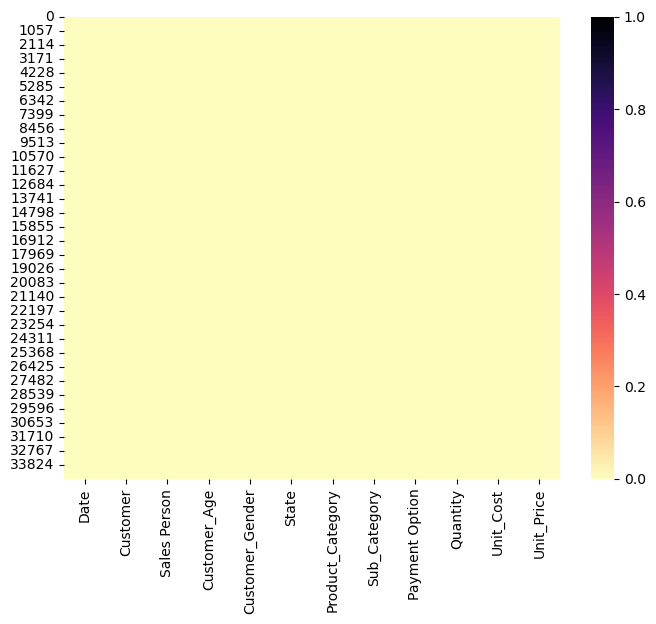

In [197]:
# Visualize the missing data
plt.figure(figsize=(8,6))
sns.heatmap(df.isnull(), cbar=True, cmap="magma_r"); # ; removes <Axes: >

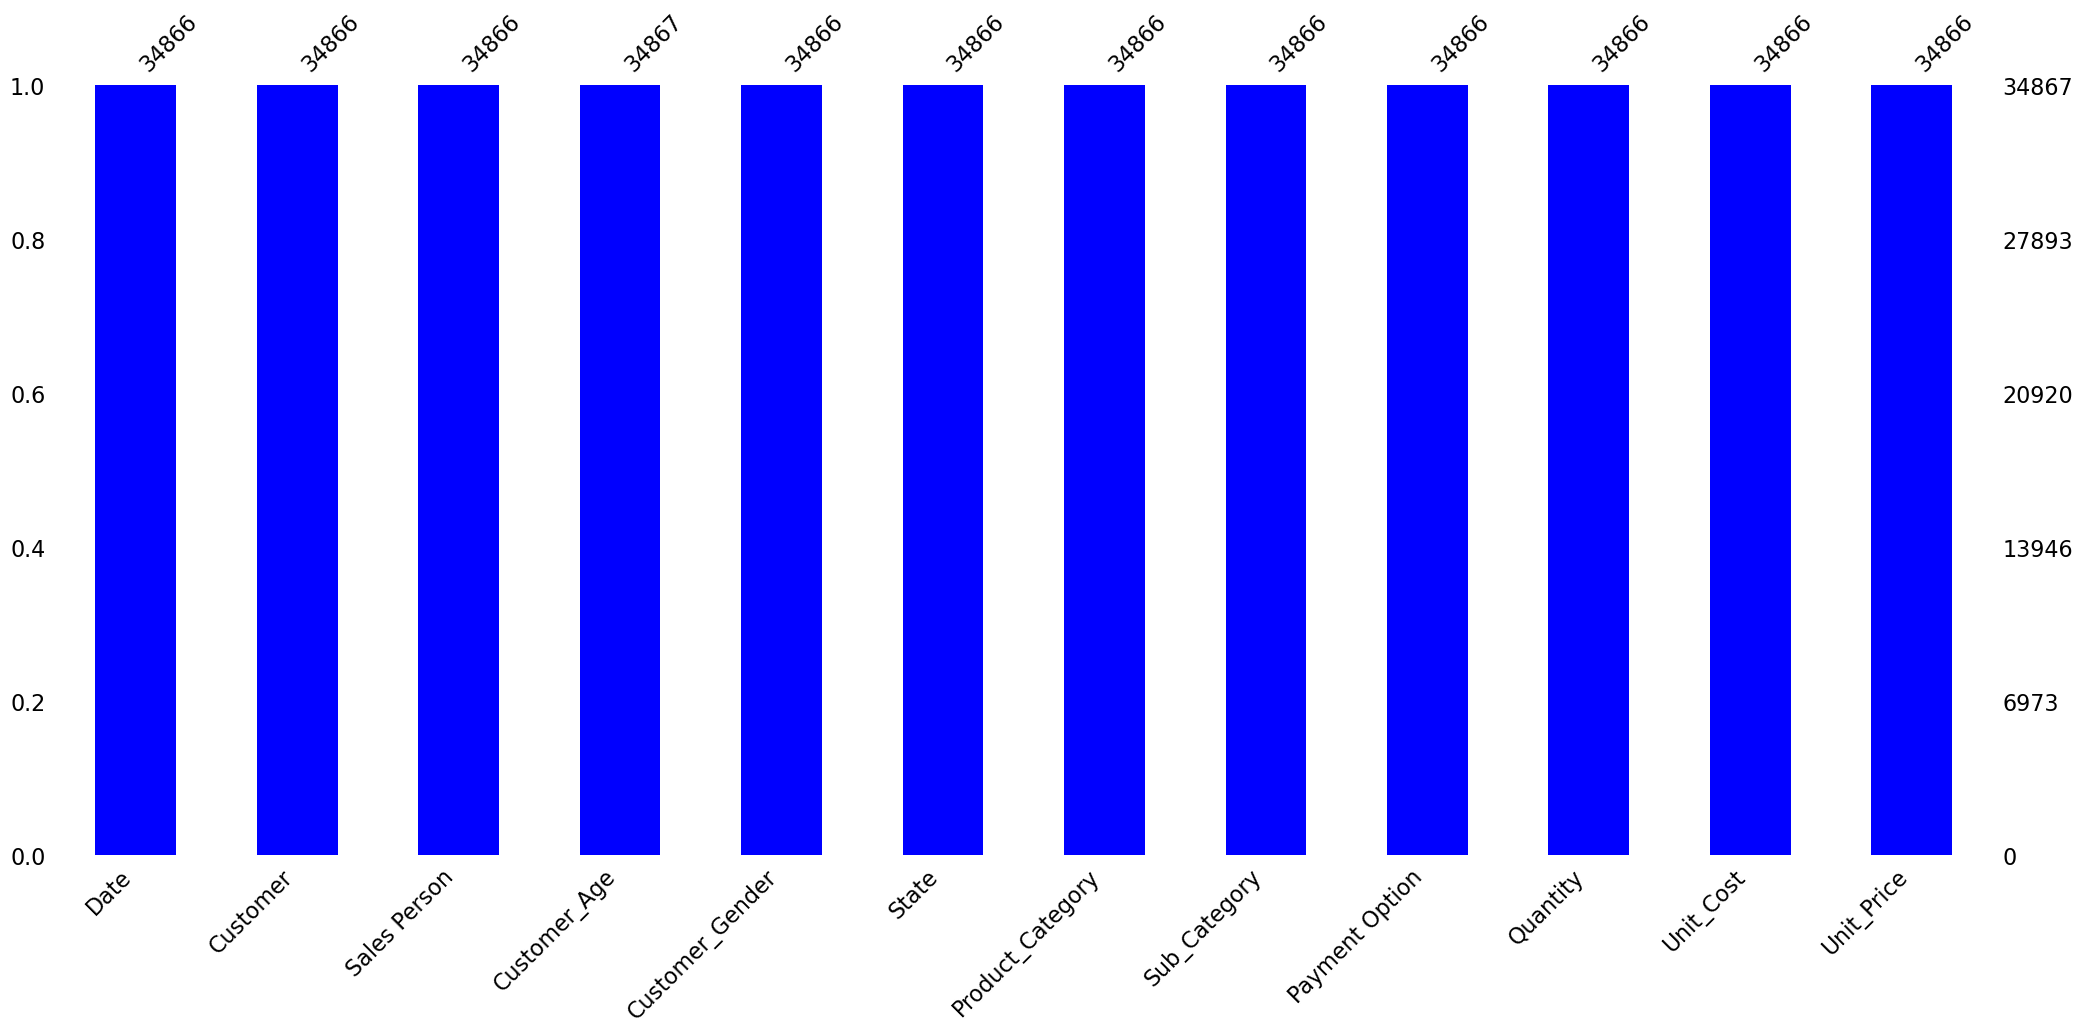

In [198]:
msno.bar(df, color="Blue"); # visualize missing data

In [199]:
# Display where the missing data exist in the data
df[df.isnull().any(axis=1)] # Look for anything thats True, which is the missing data isnull(). Returns row that has True

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,Unit_Cost,Unit_Price
34866,NaN,NaN,NaN,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [200]:
# Drop the missing data
df.dropna(inplace=True) # wihthout inplace=True, it wont drop it

In [201]:
df.isnull().sum() # confirm drop

Date                0
Customer            0
Sales Person        0
Customer_Age        0
Customer_Gender     0
State               0
Product_Category    0
Sub_Category        0
Payment Option      0
Quantity            0
Unit_Cost           0
Unit_Price          0
dtype: int64

In [202]:
# DateTime Analysis
df.head()

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,Unit_Cost,Unit_Price
0,19-Feb-16,High,Segun,29,F,Abia,Accessories,Keyboard,Online,1.0,80.00,109.00
1,20-Feb-16,High,Segun,29,F,Abia,Clothing,Polo shirts,Online,2.0,24.50,28.50
2,27-Feb-16,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,3.67,5.00
3,12-Mar-16,High,Segun,29,F,Abia,Accessories,Keyboard,Online,2.0,87.50,116.50
4,12-Mar-16,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,35.00,41.67


In [203]:
# Covert the date column to a pandas datetime object
# df.info() # Date object (string)
df["Date"] = pd.to_datetime(df["Date"])
# df.info() # Date now DateTime

# Extract the Year, Month, Quarter
df['year'] = df["Date"].dt.year
df['month'] = df["Date"].dt.month
df['month_name'] = df["Date"].dt.month_name()
df['quarter'] = df["Date"].dt.quarter

df.head()


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_23812\2189135031.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"])


,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,Unit_Cost,Unit_Price,year,month,month_name,quarter
0,2016-02-19,High,Segun,29,F,Abia,Accessories,Keyboard,Online,1.0,80.00,109.00,2016,2,February,1
1,2016-02-20,High,Segun,29,F,Abia,Clothing,Polo shirts,Online,2.0,24.50,28.50,2016,2,February,1
2,2016-02-27,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,3.67,5.00,2016,2,February,1
3,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,2.0,87.50,116.50,2016,3,March,1
4,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,35.00,41.67,2016,3,March,1


In [204]:
# Group customer age
def age_group(x):
    if x <=25:
        return "<= 25 Young Adult"
    elif x <=40:
        return "25-40 Young Adults"
    elif x <= 50:
        return "41-50 Old Adult"
    else:
        return "50+ Elders"

# Apply function to the data
df["age_group"] = df["Customer_Age"].apply(age_group)
df.head()

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,Unit_Cost,Unit_Price,year,month,month_name,quarter,age_group
0,2016-02-19,High,Segun,29,F,Abia,Accessories,Keyboard,Online,1.0,80.00,109.00,2016,2,February,1,25-40 Young Adults
1,2016-02-20,High,Segun,29,F,Abia,Clothing,Polo shirts,Online,2.0,24.50,28.50,2016,2,February,1,25-40 Young Adults
2,2016-02-27,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,3.67,5.00,2016,2,February,1,25-40 Young Adults
3,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,2.0,87.50,116.50,2016,3,March,1,25-40 Young Adults
4,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,35.00,41.67,2016,3,March,1,25-40 Young Adults


In [205]:
# Cost, Revenue, and Profit Calculations
df["cost"] = df["Quantity"]*df["Unit_Cost"]
df["revenue"] = df["Quantity"]*df["Unit_Price"]
df["profit"] = df["revenue"]*df["cost"]

df.head()

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,Unit_Cost,Unit_Price,year,month,month_name,quarter,age_group,cost,revenue,profit
0,2016-02-19,High,Segun,29,F,Abia,Accessories,Keyboard,Online,1.0,80.00,109.00,2016,2,February,1,25-40 Young Adults,80.00,109.00,8720.00
1,2016-02-20,High,Segun,29,F,Abia,Clothing,Polo shirts,Online,2.0,24.50,28.50,2016,2,February,1,25-40 Young Adults,49.00,57.00,2793.00
2,2016-02-27,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,3.67,5.00,2016,2,February,1,25-40 Young Adults,11.01,15.00,165.15
3,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,2.0,87.50,116.50,2016,3,March,1,25-40 Young Adults,175.00,233.00,40775.00
4,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,35.00,41.67,2016,3,March,1,25-40 Young Adults,105.00,125.01,13126.05


In [206]:
# Profit/Loss Grouping
def profit_or_loss(x):
    if x > 0:
        return "Profit"
    elif x < 0:
        return "Loss"
    else:
        return "Break Even"

df["profit_label"] = df["profit"].apply(profit_or_loss)

df.head()

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,...,Unit_Price,year,month,month_name,quarter,age_group,cost,revenue,profit,profit_label
0,2016-02-19,High,Segun,29,F,Abia,Accessories,Keyboard,Online,1.0,...,109.00,2016,2,February,1,25-40 Young Adults,80.00,109.00,8720.00,Profit
1,2016-02-20,High,Segun,29,F,Abia,Clothing,Polo shirts,Online,2.0,...,28.50,2016,2,February,1,25-40 Young Adults,49.00,57.00,2793.00,Profit
2,2016-02-27,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,...,5.00,2016,2,February,1,25-40 Young Adults,11.01,15.00,165.15,Profit
3,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,2.0,...,116.50,2016,3,March,1,25-40 Young Adults,175.00,233.00,40775.00,Profit
4,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,...,41.67,2016,3,March,1,25-40 Young Adults,105.00,125.01,13126.05,Profit


### Univariate Analysis

### It involves analyzing the distribution of and summary staistics of individual variable/column/feature

1. Numerical column/feature = Numerical Visualiztion Techniques
2. Categorical column/feature = Categorical Visualiztion Techniques
3. Examiming each column

#### Categorical data visualiztion

In [207]:
df.columns

Index(['Date', 'Customer', 'Sales Person', 'Customer_Age', 'Customer_Gender',
       'State', 'Product_Category', 'Sub_Category', 'Payment Option',
       'Quantity', 'Unit_Cost', 'Unit_Price', 'year', 'month', 'month_name',
       'quarter', 'age_group', 'cost', 'revenue', 'profit', 'profit_label'],
      dtype='object')

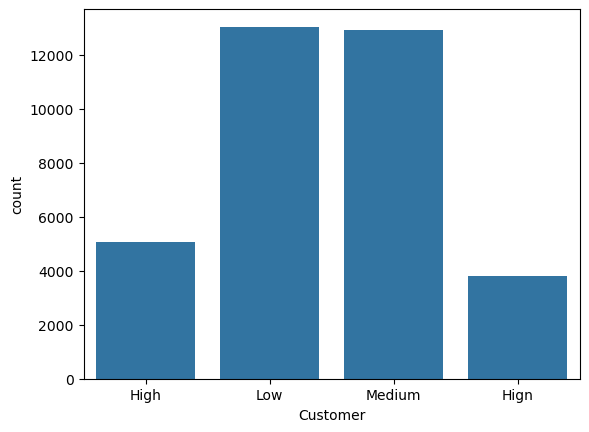

In [208]:
# How many customers(object/string/categorical feature) below each customer spec
sns.countplot(x="Customer", data=df); # error: Hign instead of High

In [209]:
df.head()

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,...,Unit_Price,year,month,month_name,quarter,age_group,cost,revenue,profit,profit_label
0,2016-02-19,High,Segun,29,F,Abia,Accessories,Keyboard,Online,1.0,...,109.00,2016,2,February,1,25-40 Young Adults,80.00,109.00,8720.00,Profit
1,2016-02-20,High,Segun,29,F,Abia,Clothing,Polo shirts,Online,2.0,...,28.50,2016,2,February,1,25-40 Young Adults,49.00,57.00,2793.00,Profit
2,2016-02-27,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,...,5.00,2016,2,February,1,25-40 Young Adults,11.01,15.00,165.15,Profit
3,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,2.0,...,116.50,2016,3,March,1,25-40 Young Adults,175.00,233.00,40775.00,Profit
4,2016-03-12,High,Segun,29,F,Abia,Accessories,Keyboard,Online,3.0,...,41.67,2016,3,March,1,25-40 Young Adults,105.00,125.01,13126.05,Profit


In [210]:
# Investigate the columns affected
df[df["Customer"] == "Hign"].head()

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,...,Unit_Price,year,month,month_name,quarter,age_group,cost,revenue,profit,profit_label
29770,2015-08-03,Hign,Derick,28,F,Lagos,Phones,IPhone,Cash,1.0,...,2136.00,2015,8,August,3,25-40 Young Adults,2295.00,2136.00,4.902120e+06,Profit
29771,2015-08-04,Hign,Derick,28,F,Lagos,Accessories,Keyboard,Cash,2.0,...,19.50,2015,8,August,3,25-40 Young Adults,35.00,39.00,1.365000e+03,Profit
29772,2015-08-04,Hign,Derick,28,F,Lagos,Accessories,Keyboard,Cash,3.0,...,18.67,2015,8,August,3,25-40 Young Adults,50.01,56.01,2.801060e+03,Profit
29773,2015-08-10,Hign,Derick,28,F,Lagos,Accessories,Keyboard,Cash,1.0,...,69.00,2015,8,August,3,25-40 Young Adults,60.00,69.00,4.140000e+03,Profit
29774,2015-08-25,Hign,Derick,28,F,Lagos,Accessories,Keyboard,Cash,3.0,...,47.00,2015,8,August,3,25-40 Young Adults,125.01,141.00,1.762641e+04,Profit


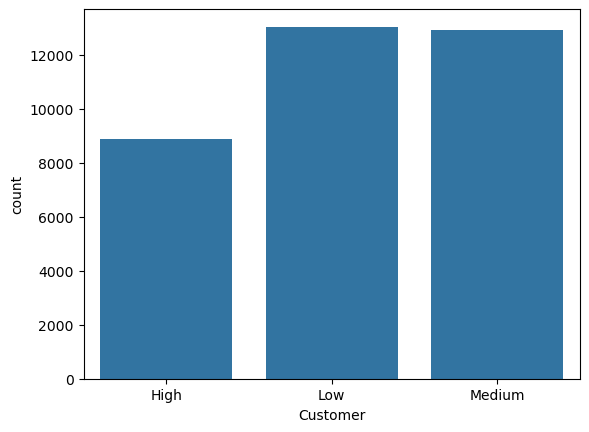

In [211]:
# Correct the spelling of HIGN
df.loc[df["Customer"] == "Hign", "Customer"] = "High"
sns.countplot(x="Customer", data=df);



In [212]:
df["Customer"].value_counts()

Customer
Low       13041
Medium    12926
High       8899
Name: count, dtype: int64

##### Narration about your observation

1. Low customers made the most transations

In [213]:
df.columns

Index(['Date', 'Customer', 'Sales Person', 'Customer_Age', 'Customer_Gender',
       'State', 'Product_Category', 'Sub_Category', 'Payment Option',
       'Quantity', 'Unit_Cost', 'Unit_Price', 'year', 'month', 'month_name',
       'quarter', 'age_group', 'cost', 'revenue', 'profit', 'profit_label'],
      dtype='object')

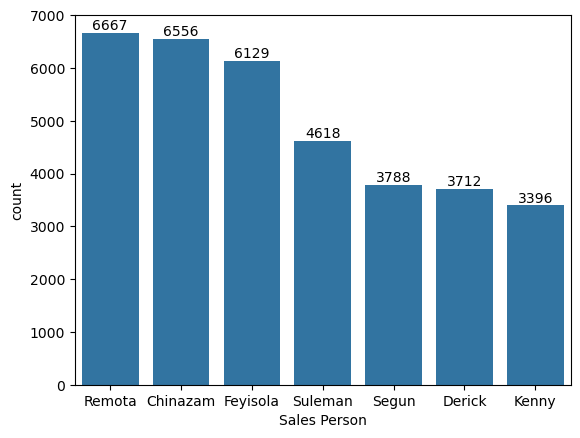

In [214]:
# Sales Person - How many transaction by sales person
ax = sns.countplot(x=df["Sales Person"], order=df["Sales Person"].value_counts(ascending=False).index)
values = df["Sales Person"].value_counts(ascending=False).values
ax.bar_label(container=ax.containers[0], labels=values);

##### Narration about this observation

Sales person: Remota made the most sales 

In [215]:
df.columns

Index(['Date', 'Customer', 'Sales Person', 'Customer_Age', 'Customer_Gender',
       'State', 'Product_Category', 'Sub_Category', 'Payment Option',
       'Quantity', 'Unit_Cost', 'Unit_Price', 'year', 'month', 'month_name',
       'quarter', 'age_group', 'cost', 'revenue', 'profit', 'profit_label'],
      dtype='object')

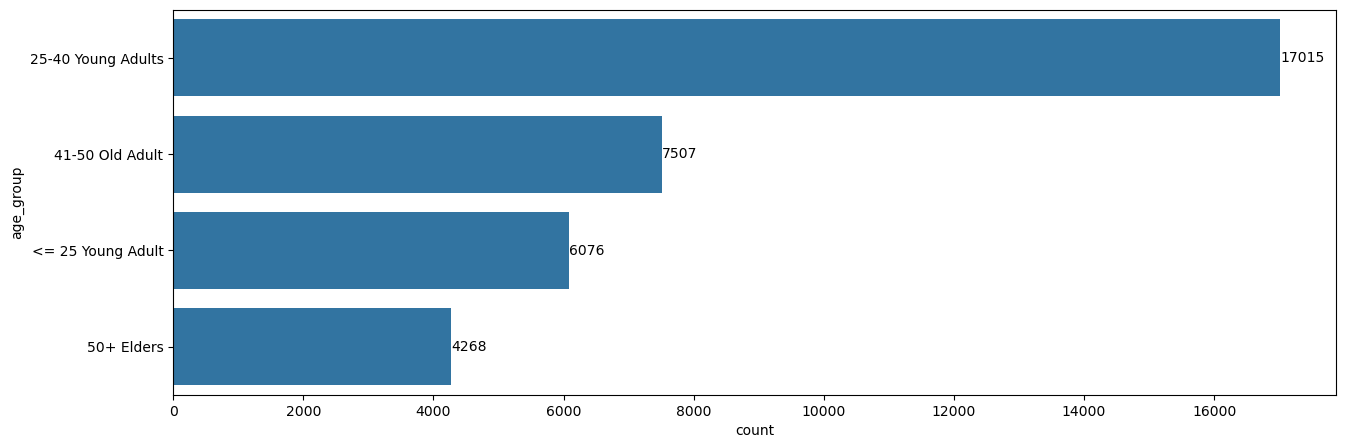

In [216]:
# Total transactions by Customer Age Group
plt.figure(figsize=(15,5))

ax = sns.countplot(y=df["age_group"], order=df["age_group"].value_counts(ascending=False).index)
values = df["age_group"].value_counts(ascending=False).values
ax.bar_label(container=ax.containers[0], labels=values);

#### Narration

Age group: Young adults between 25 and 40 made more transactions with old adults, 41-50, coming up next

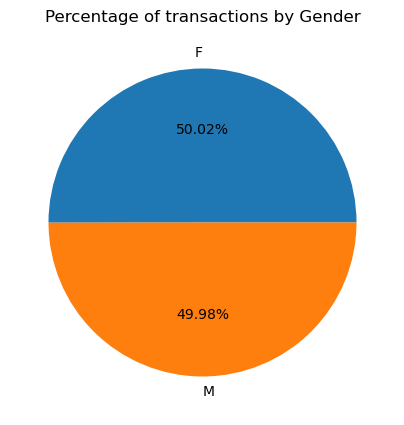

In [217]:
# Total transation by Customer Gender

fig,ax = plt.subplots(figsize=(5,5))
count = Counter(df["Customer_Gender"])
ax.pie(count.values(), labels=count.keys(), autopct=lambda p:f'{p:.2f}%')
ax.set_title("Percentage of transactions by Gender")
plt.show()

#### Narration

Gender: nearly perfectly balanced

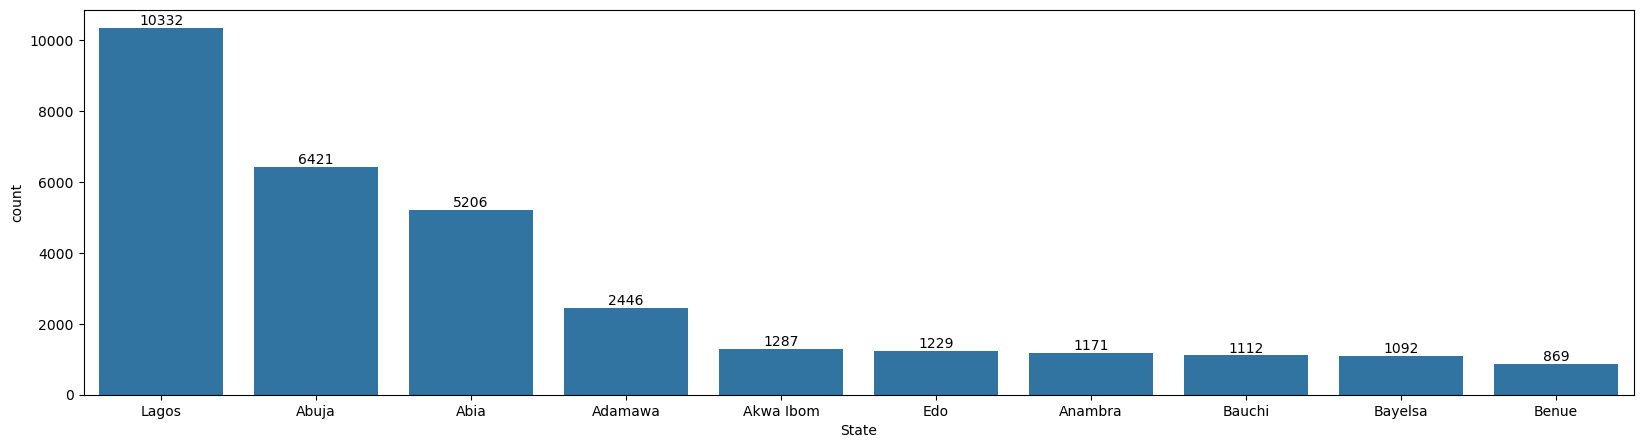

State
Lagos        10332
Abuja         6421
Abia          5206
Adamawa       2446
Akwa Ibom     1287
Edo           1229
Anambra       1171
Bauchi        1112
Bayelsa       1092
Benue          869
Name: count, dtype: int64


In [218]:
# Top 10 transaction by state
plt.figure(figsize=(20,5))
topten = df["State"].value_counts().head(10)
ax = sns.countplot(x="State", data=df, order=topten.index);
ax.bar_label(ax.containers[0])
plt.show()
print(topten)

#### Narration

State: Most transactions came from Lagos

### TODO - Categorical
- Product Category
- Sub Category
- Payment Option
- Month Name

In [219]:
df[df["profit_label"] == "Loss"].head()

,Date,Customer,Sales Person,Customer_Age,Customer_Gender,State,Product_Category,Sub_Category,Payment Option,Quantity,...,Unit_Price,year,month,month_name,quarter,age_group,cost,revenue,profit,profit_label


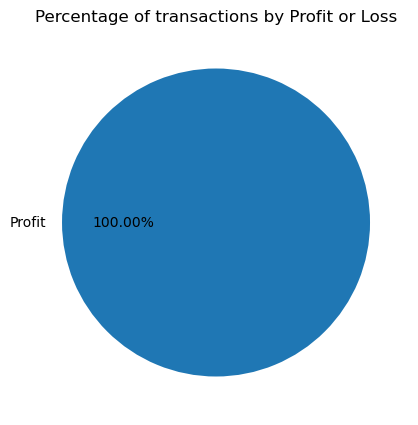

In [220]:
# Total transation by Profit or Loss

fig,ax = plt.subplots(figsize=(5,5))
count = Counter(df["profit_label"])
ax.pie(count.values(), labels=count.keys(), autopct=lambda p:f'{p:.2f}%')
ax.set_title("Percentage of transactions by Profit or Loss")
plt.show()

### Narration - Profit and Loss

- Only profit was generated - 100%

### Numerical Data Visualizations

Text(0.5, 1.0, 'Histogram on Profit')

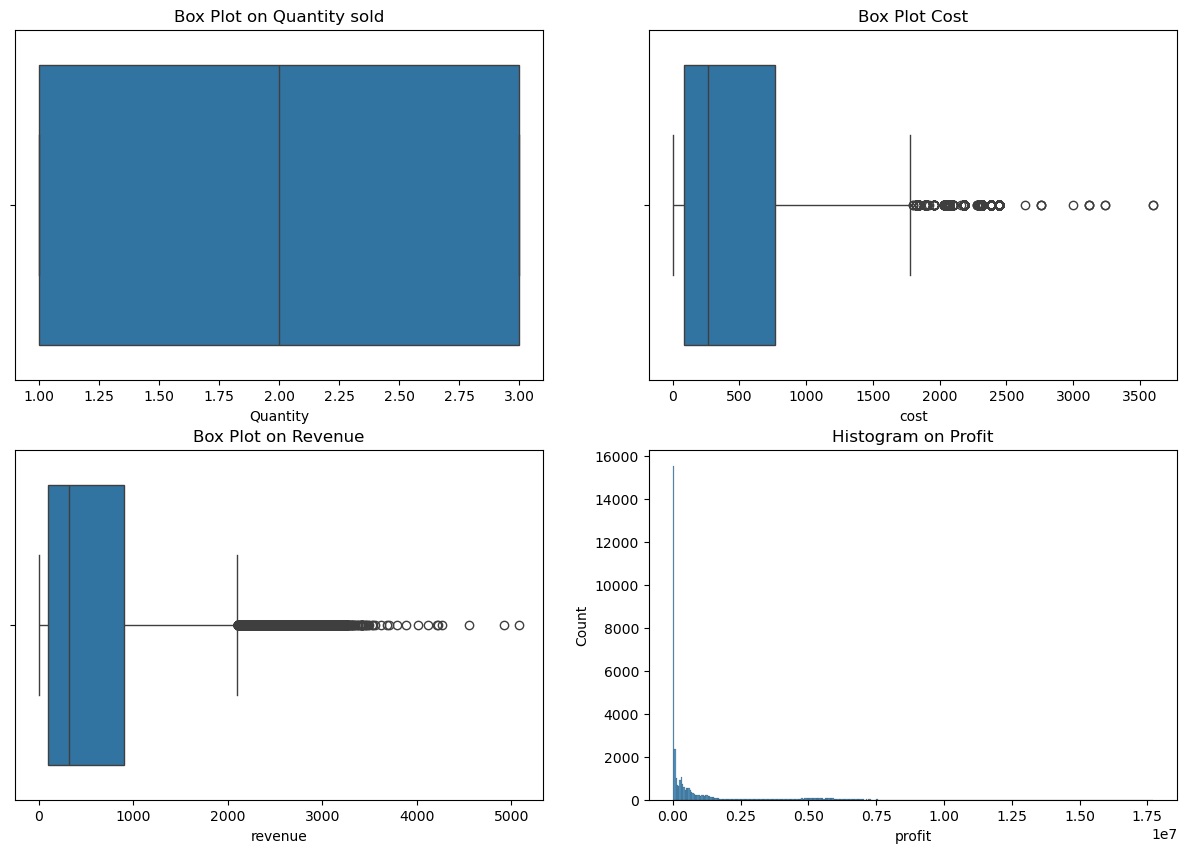

In [221]:
# Quantity, Cost, Revenue and Profit - subplot

fig, axs = plt.subplots(nrows=2,ncols=2,figsize=(15,10))

sns.boxplot(x="Quantity", data=df, ax=axs[0,0])
axs[0,0].set_title("Box Plot on Quantity sold")

sns.boxplot(x="cost", data=df, ax=axs[0,1])
axs[0,1].set_title("Box Plot Cost")


sns.boxplot(x="revenue", data=df, ax=axs[1,0])
axs[1,0].set_title("Box Plot on Revenue")


sns.histplot(x="profit", data=df, ax=axs[1,1])
axs[1,1].set_title("Histogram on Profit")

### Narration

#### Bivariate Analysis

##### It involves analyzing the relationship between two variables

- Focuus on Profit

#### Univariate focuses on one variable, Bivariate focuses on two

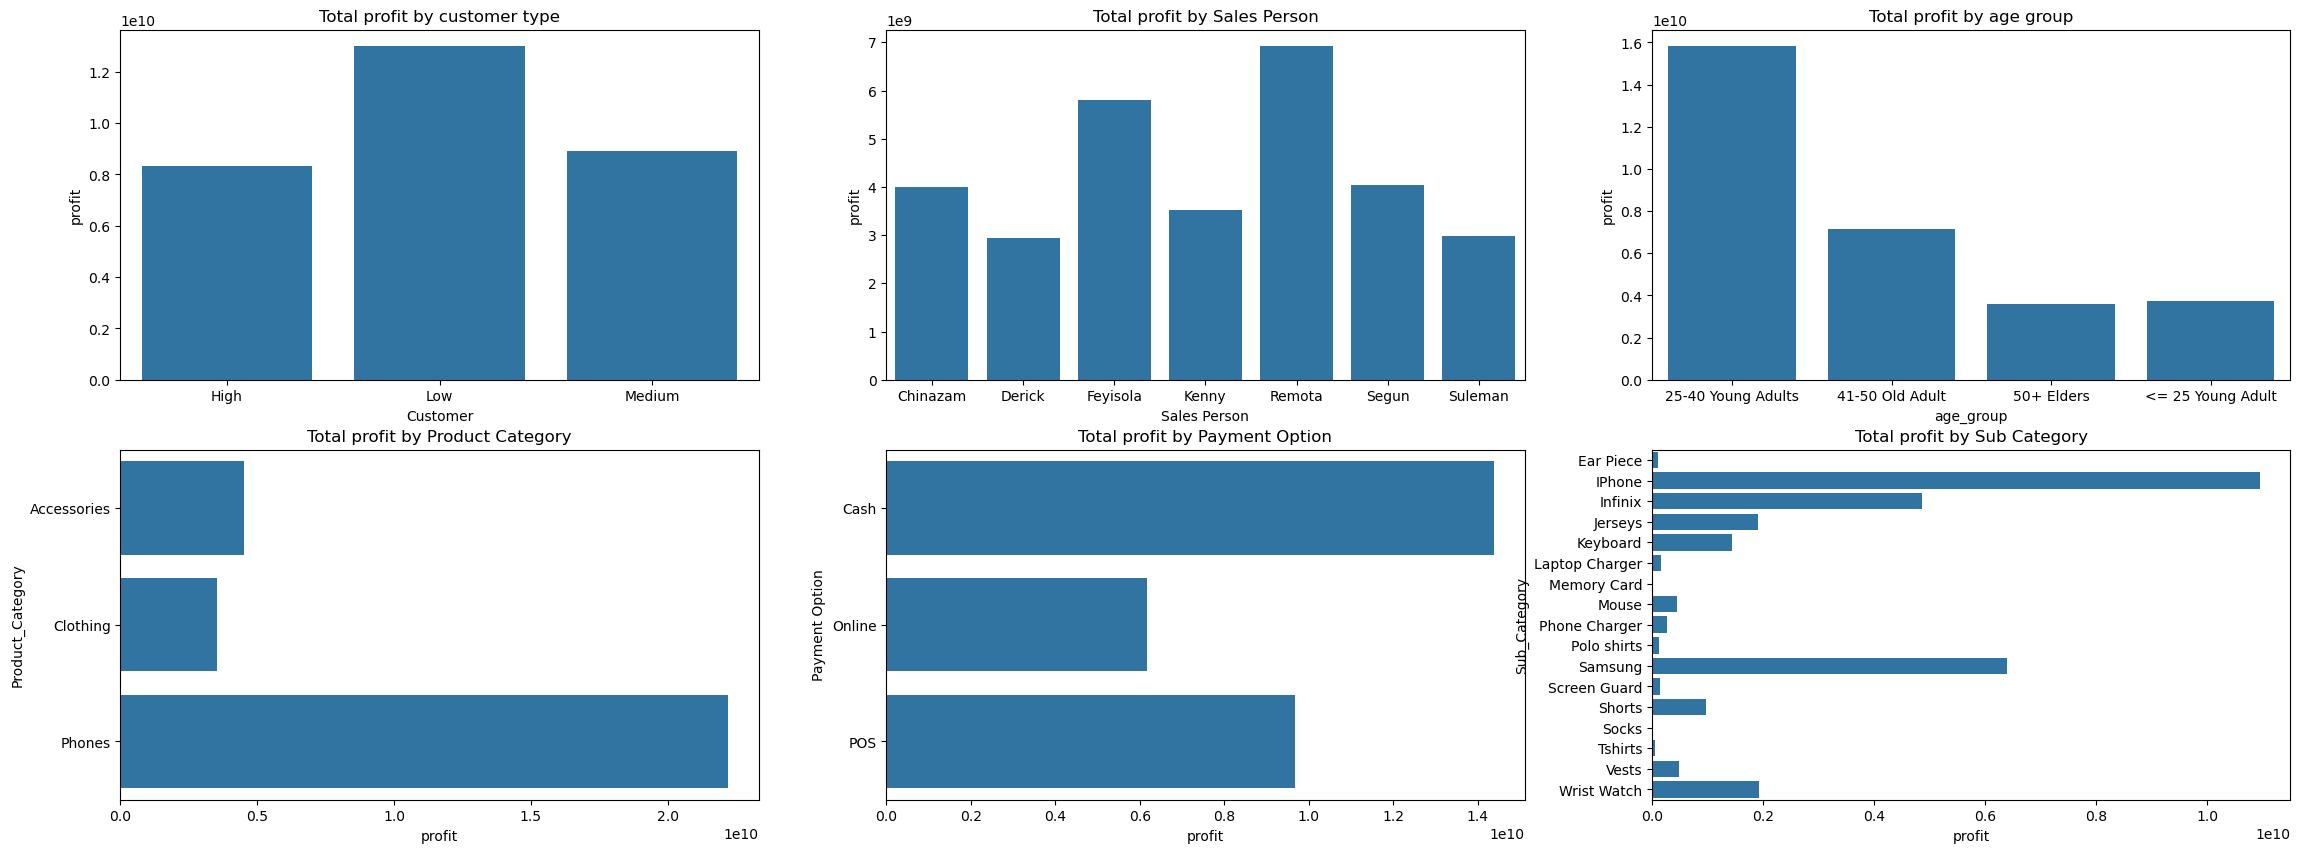

In [222]:
# Customer and Profit - subplot

fig, axs = plt.subplots(nrows=2,ncols=3,figsize=(28,10))

# customers v profit
cust_prof = df.groupby("Customer")["profit"].sum().reset_index()
sns.barplot(x='Customer', data=cust_prof, y='profit', ax=axs[0,0])
axs[0,0].set_title("Total profit by customer type");

# Sales Person v profit
sp_prof = df.groupby("Sales Person")["profit"].sum().reset_index()
sns.barplot(x='Sales Person', data=sp_prof, y='profit', ax=axs[0,1])
axs[0,1].set_title("Total profit by Sales Person");

# Age group v profit
age_prof = df.groupby("age_group")["profit"].sum().reset_index()
sns.barplot(x='age_group', data=age_prof, y='profit', ax=axs[0,2])
axs[0,2].set_title("Total profit by age group");

# Product category v profit
pc_prof = df.groupby("Product_Category")["profit"].sum().reset_index()
sns.barplot(y='Product_Category', data=pc_prof, x='profit', ax=axs[1,0])
axs[1,0].set_title("Total profit by Product Category");

# Payment option v profit
po_prof = df.groupby("Payment Option")["profit"].sum().reset_index()
sns.barplot(y='Payment Option', data=po_prof, x='profit', ax=axs[1,1])
axs[1,1].set_title("Total profit by Payment Option");

# Sub Category v profit
sc_prof = df.groupby("Sub_Category")["profit"].sum().reset_index()
sns.barplot(y='Sub_Category', data=sc_prof, x='profit', ax=axs[1,2])
axs[1,2].set_title("Total profit by Sub Category");

#### Narration

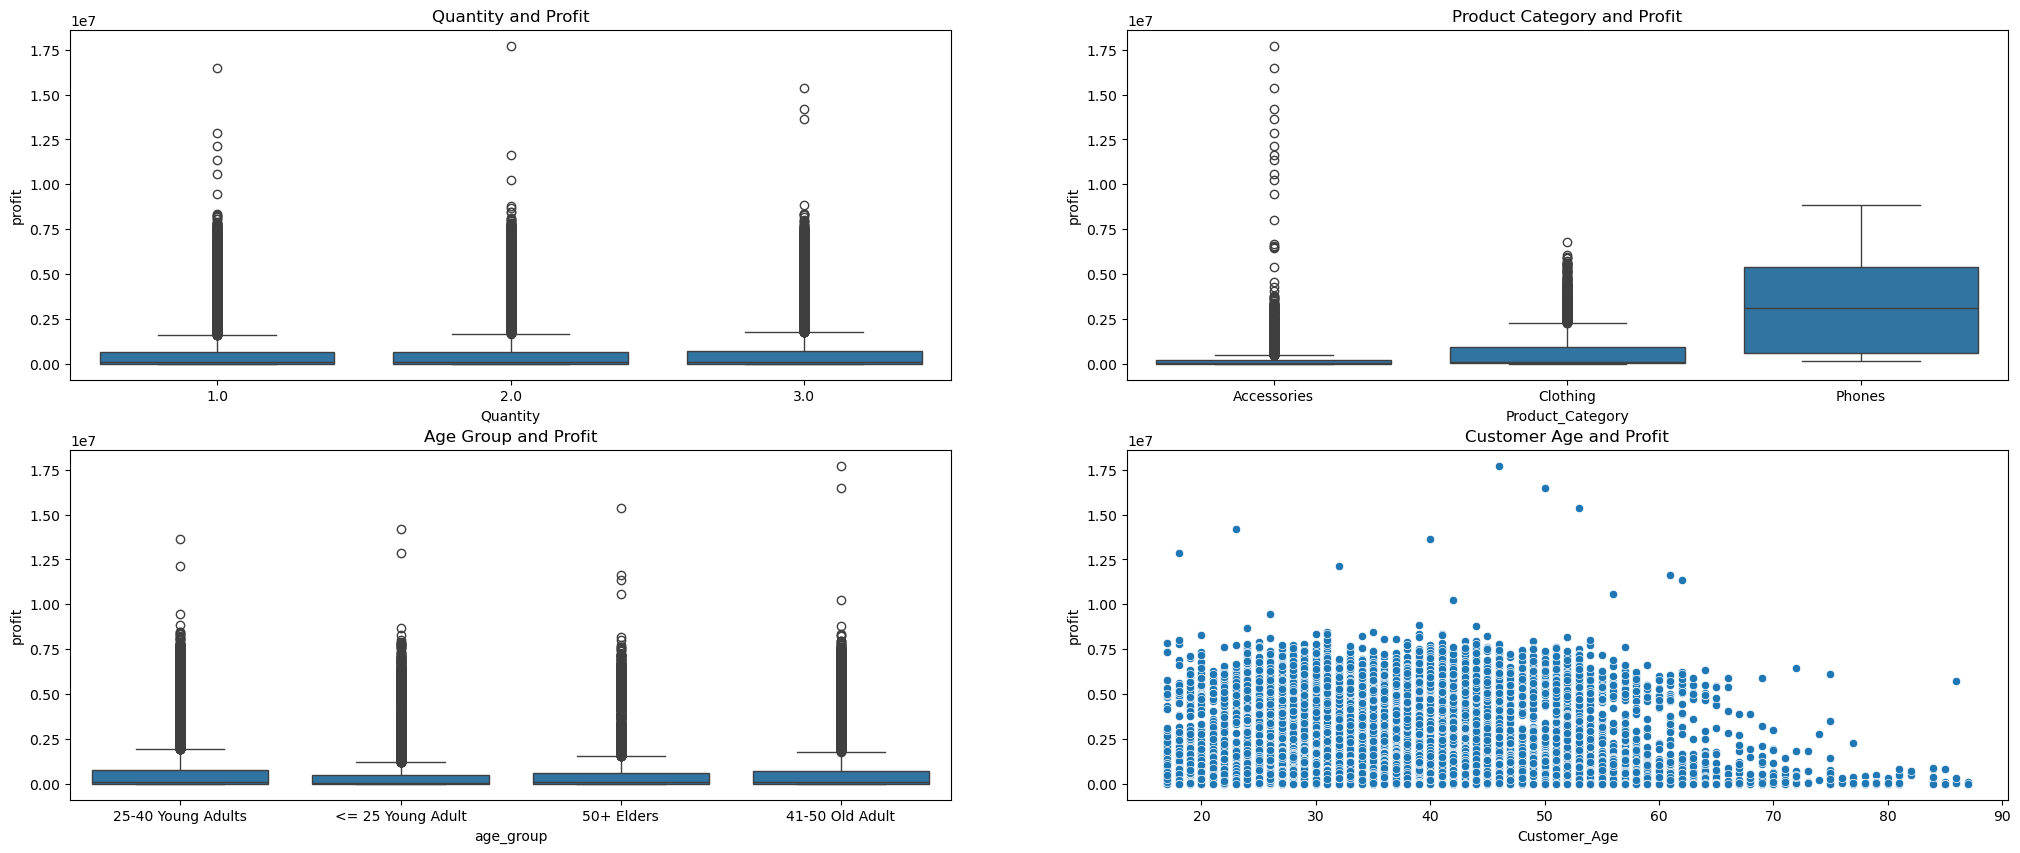

In [223]:
# Numerical columns

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(25,10))

sns.boxplot(x='Quantity', y='profit', data=df, ax=axs[0,0])
axs[0,0].set_title("Quantity and Profit");

sns.boxplot(x='Product_Category', y='profit', data=df, ax=axs[0,1])
axs[0,1].set_title("Product Category and Profit");

sns.boxplot(x='age_group', y='profit', data=df, ax=axs[1,0])
axs[1,0].set_title("Age Group and Profit");

# scatter plot checks the relationship between tw numerical columns
sns.scatterplot(x='Customer_Age', y='profit', data=df, ax=axs[1,1])
axs[1,1].set_title("Customer Age and Profit");

#### Narrations

### Multivariate

#### Three or more columns

In [224]:
df.columns

Index(['Date', 'Customer', 'Sales Person', 'Customer_Age', 'Customer_Gender',
       'State', 'Product_Category', 'Sub_Category', 'Payment Option',
       'Quantity', 'Unit_Cost', 'Unit_Price', 'year', 'month', 'month_name',
       'quarter', 'age_group', 'cost', 'revenue', 'profit', 'profit_label'],
      dtype='object')

<Axes: xlabel='Product_Category', ylabel='Total'>

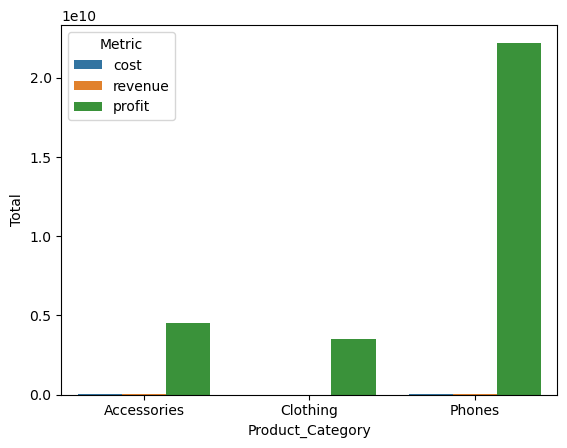

In [228]:
# Product Category against Cost, Revenue and Profit

procat = df.groupby("Product_Category")[["cost", "revenue", "profit"]].sum().reset_index()
procat = pd.melt(procat, id_vars="Product_Category", var_name="Metric", value_name="Total")

sns.barplot(data=procat, x="Product_Category", y="Total", hue="Metric")

### Narration

In [226]:
df["profit_label"].value_counts()

profit_label
Profit    34866
Name: count, dtype: int64

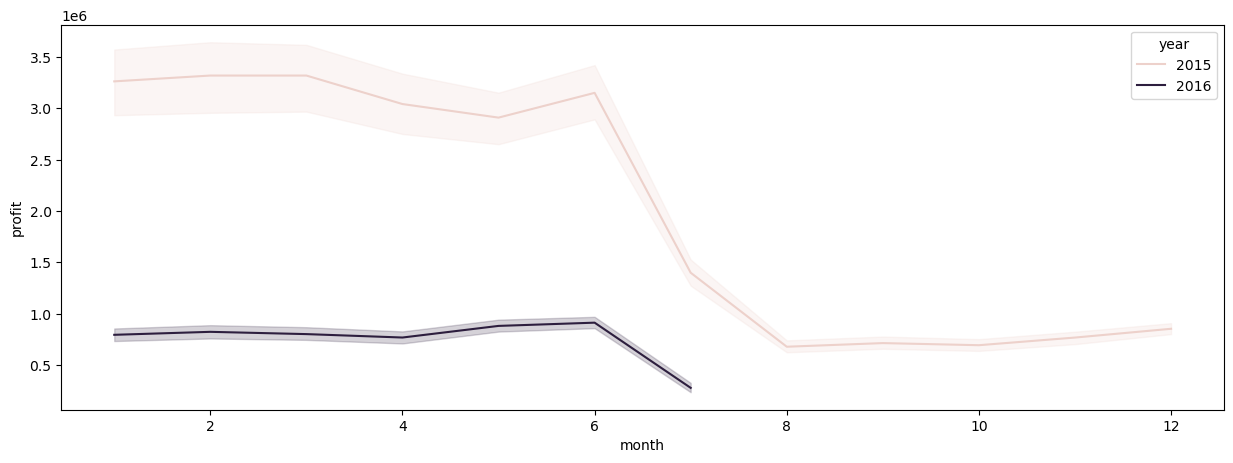

In [233]:
plt.figure(figsize=(15,5))
sns.lineplot(x='month', y='profit', data=df, hue='year');

In [234]:
# Using pivot table
df.pivot_table(values='profit', index='year', columns='month', aggfunc='sum')

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2015,4.501784e+08,5.111041e+08,4.944988e+08,5.383578e+08,5.935419e+08,6.490033e+08,1.299592e+09,1.567974e+09,1.648583e+09,1.775875e+09,1.915008e+09,2.919280e+09
2016,2.205396e+09,2.255808e+09,2.414614e+09,2.391769e+09,3.066106e+09,3.177363e+09,3.605474e+08,NaN,NaN,NaN,NaN,NaN


### Narrations

<Axes: xlabel='Customer_Gender', ylabel='profit'>

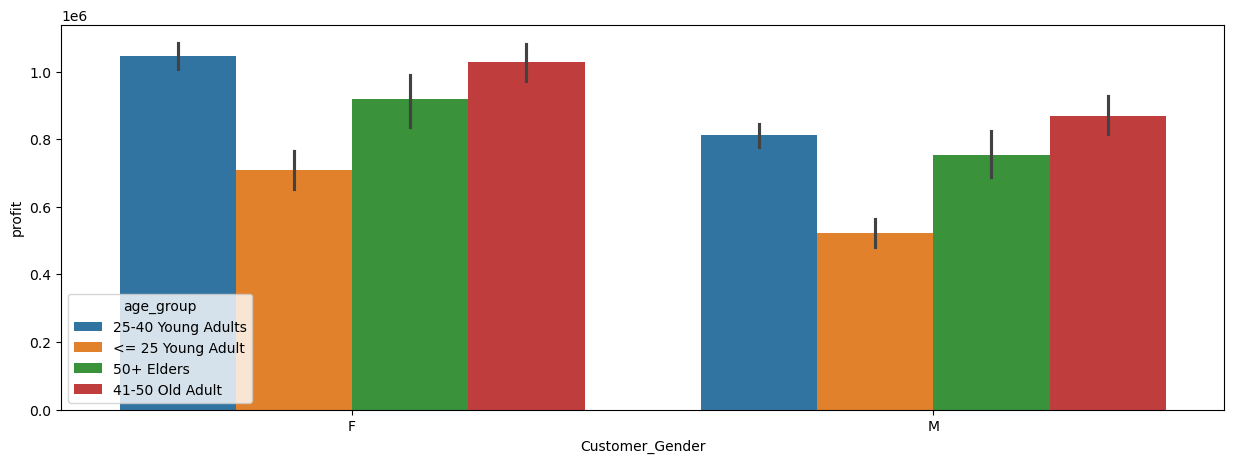

In [236]:
# Customer Gender, Age Group and Profit
plt.figure(figsize=(15,5))
sns.barplot(x="Customer_Gender", y='profit', data=df, hue="age_group")

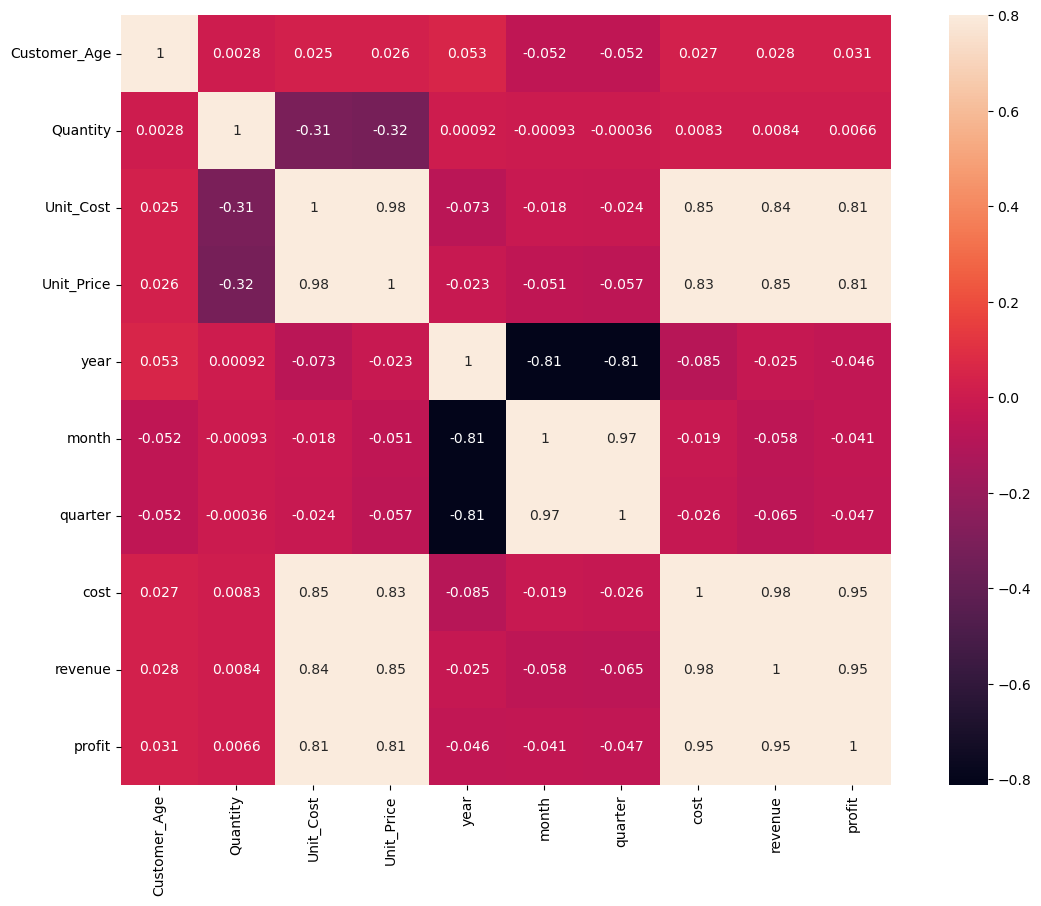

In [243]:
# Correlation 

# Correlation
a = df.corr(numeric_only=True)
plt.subplots(figsize=(15,10))
sns.heatmap(a, vmax=.8, square=True, annot=True);

### Narrations

c:\Users\LENOVO\anaconda3\Lib\site-packages\seaborn\axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


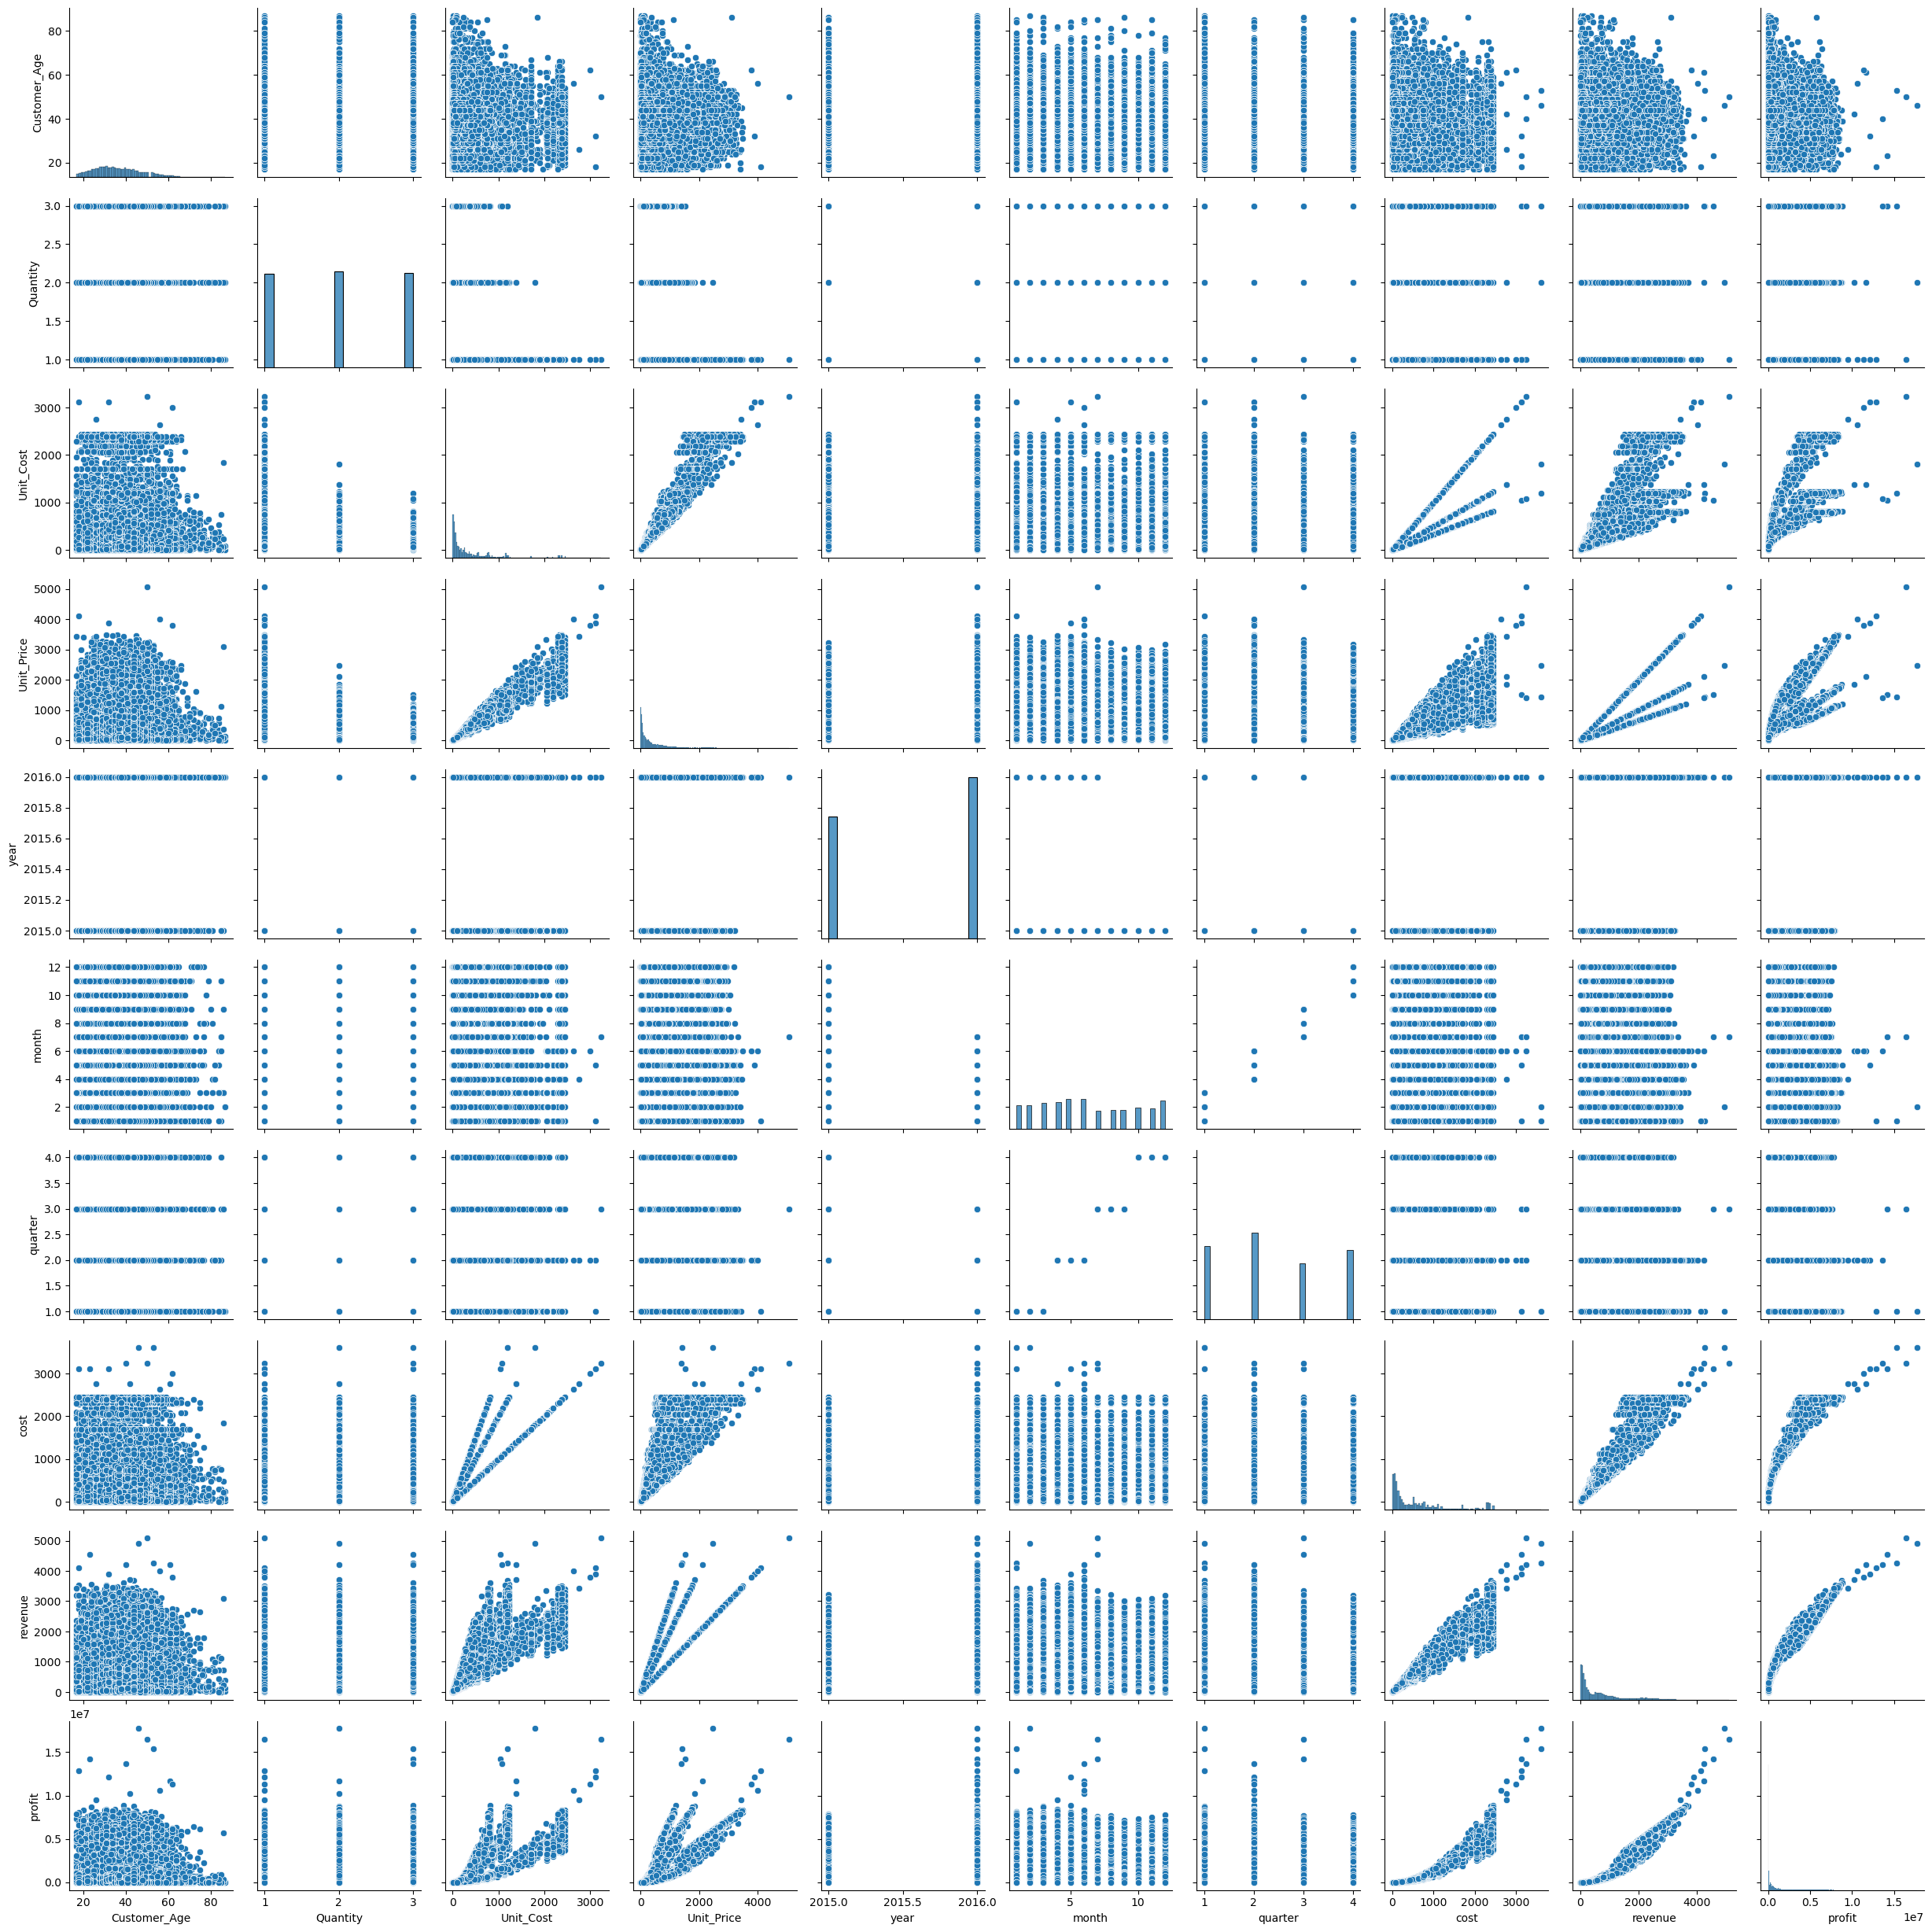

In [244]:
sns.pairplot(df, size=2.5);

### Narrations